In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, ConfusionMatrixDisplay)
from sklearn.utils import resample

plt.style.use('seaborn-v0_8-whitegrid')
print("✅ Library berhasil diimport!")

✅ Library berhasil diimport!


# **Data Understanding**

In [2]:
# Load dataset
df = pd.read_csv('/kaggle/input/datasets/aliafzal9323/chicago-crime-dataset-2024-2026/chicago crimes.csv')

print(f"Jumlah baris  : {df.shape[0]:,}")
print(f"Jumlah kolom  : {df.shape[1]}")

Jumlah baris  : 8,500,901
Jumlah kolom  : 22


In [3]:
print("\nPreview Data :")
df


Preview Data :


,ID,Case Number,Date,Block,IUCR,Primary Type,Description,Location Description,Arrest,Domestic,...,Ward,Community Area,FBI Code,X Coordinate,Y Coordinate,Year,Updated On,Latitude,Longitude,Location
0,13311263,JG503434,07/29/2022 03:39:00 AM,023XX S TROY ST,1582,OFFENSE INVOLVING CHILDREN,CHILD PORNOGRAPHY,RESIDENCE,True,False,...,25.0,30.0,17,NaN,NaN,2022,04/18/2024 03:40:59 PM,NaN,NaN,NaN
1,13053066,JG103252,01/03/2023 04:44:00 PM,039XX W WASHINGTON BLVD,2017,NARCOTICS,MANUFACTURE / DELIVER - CRACK,SIDEWALK,True,False,...,28.0,26.0,18,NaN,NaN,2023,01/20/2024 03:41:12 PM,NaN,NaN,NaN
2,12131221,JD327000,08/10/2020 09:45:00 AM,015XX N DAMEN AVE,0326,ROBBERY,AGGRAVATED VEHICULAR HIJACKING,STREET,True,False,...,1.0,24.0,03,1162795.0,1909900.0,2020,05/17/2025 03:40:52 PM,41.908418,-87.677407,"(41.908417822, -87.67740693)"
3,11227634,JB147599,08/26/2017 10:00:00 AM,001XX W RANDOLPH ST,0281,CRIM SEXUAL ASSAULT,NON-AGGRAVATED,HOTEL/MOTEL,False,False,...,42.0,32.0,02,NaN,NaN,2017,02/11/2018 03:57:41 PM,NaN,NaN,NaN
4,13203321,JG415333,09/06/2023 05:00:00 PM,002XX N Wells st,1320,CRIMINAL DAMAGE,TO VEHICLE,PARKING LOT / GARAGE (NON RESIDENTIAL),False,False,...,42.0,32.0,14,1174694.0,1901831.0,2023,11/04/2023 03:40:18 PM,41.886018,-87.633938,"(41.886018055, -87.633937881)"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8500896,14012613,JJ463710,10/16/2025 01:28:00 PM,015XX S KENNETH AVE,1752,OFFENSE INVOLVING CHILDREN,AGGRAVATED CRIMINAL SEXUAL ABUSE BY FAMILY MEMBER,RESIDENCE,False,True,...,24.0,29.0,17,1146973.0,1892034.0,2025,11/02/2025 03:41:09 PM,41.859709,-87.735986,"(41.859708775, -87.735986352)"
8500897,14011813,JJ468463,10/18/2025 11:30:00 AM,102XX W ZEMKE RD,1206,DECEPTIVE PRACTICE,"THEFT BY LESSEE, MOTOR VEHICLE",AIRPORT BUILDING NON-TERMINAL - NON-SECURE AREA,False,False,...,41.0,76.0,11,1106961.0,1941092.0,2025,11/02/2025 03:41:09 PM,41.995002,-87.881915,"(41.995001671, -87.881914976)"
8500898,14001853,JJ456646,10/18/2025 05:34:00 PM,016XX S ASHLAND AVE,0810,THEFT,OVER $500,APARTMENT,False,False,...,25.0,31.0,06,1165987.0,1892014.0,2025,11/02/2025 03:41:09 PM,41.859270,-87.666192,"(41.859269673, -87.666191925)"
8500899,14006760,JJ462617,10/23/2025 03:54:00 PM,032XX N CLARK ST,1330,CRIMINAL TRESPASS,TO LAND,DEPARTMENT STORE,False,False,...,44.0,6.0,26,1169868.0,1921628.0,2025,11/02/2025 03:41:09 PM,41.940449,-87.651082,"(41.94044868, -87.651081589)"


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8500901 entries, 0 to 8500900
Data columns (total 22 columns):
 #   Column                Dtype  
---  ------                -----  
 0   ID                    int64  
 1   Case Number           object 
 2   Date                  object 
 3   Block                 object 
 4   IUCR                  object 
 5   Primary Type          object 
 6   Description           object 
 7   Location Description  object 
 8   Arrest                bool   
 9   Domestic              bool   
 10  Beat                  int64  
 11  District              float64
 12  Ward                  float64
 13  Community Area        float64
 14  FBI Code              object 
 15  X Coordinate          float64
 16  Y Coordinate          float64
 17  Year                  int64  
 18  Updated On            object 
 19  Latitude              float64
 20  Longitude             float64
 21  Location              object 
dtypes: bool(2), float64(7), int64(3), object(1

In [5]:
# Cek missing values

print("\n Missing Values per Kolom:")
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
missing_df[missing_df['Missing Count'] > 0]


 Missing Values per Kolom:


,Missing Count,Missing %
Location Description,15626,0.18
District,47,0.00
Ward,614818,7.23
Community Area,613685,7.22
X Coordinate,94671,1.11
Y Coordinate,94671,1.11
Latitude,94671,1.11
Longitude,94671,1.11
Location,94671,1.11


In [6]:
# Distribusi Target Variable
print("\nDistribusi Target Variabel (Arrest):")
arrest_counts = df['Arrest'].value_counts()
arrest_pct = df['Arrest'].value_counts(normalize=True) * 100
pd.DataFrame({'Jumlah': arrest_counts, 'Persentase (%)': arrest_pct.round(2)})


Distribusi Target Variabel (Arrest):


,Jumlah,Persentase (%)
Arrest,,
False,6363326,74.85
True,2137575,25.15


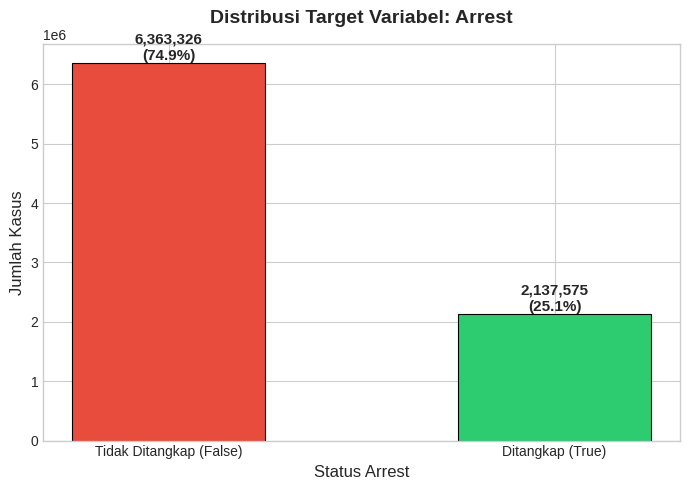

In [7]:
# Distribusi Target (Arrest)
fig, ax = plt.subplots(figsize=(7, 5))

arrest_counts = df['Arrest'].value_counts()
colors = ['#E74C3C', '#2ECC71']
bars = ax.bar(
    ['Tidak Ditangkap (False)', 'Ditangkap (True)'],
    arrest_counts.values,
    color=colors,
    edgecolor='black',
    linewidth=0.8,
    width=0.5
)

for bar, val in zip(bars, arrest_counts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 50,
        f'{val:,}\n({val / len(df) * 100:.1f}%)',
        ha='center', va='bottom', fontweight='bold', fontsize=11
    )

ax.set_title('Distribusi Target Variabel: Arrest', fontsize=14, fontweight='bold', pad=15)
ax.set_ylabel('Jumlah Kasus', fontsize=12)
ax.set_xlabel('Status Arrest', fontsize=12)

plt.tight_layout()
plt.savefig('plot1_distribusi_arrest.png', dpi=150, bbox_inches='tight')
plt.show()

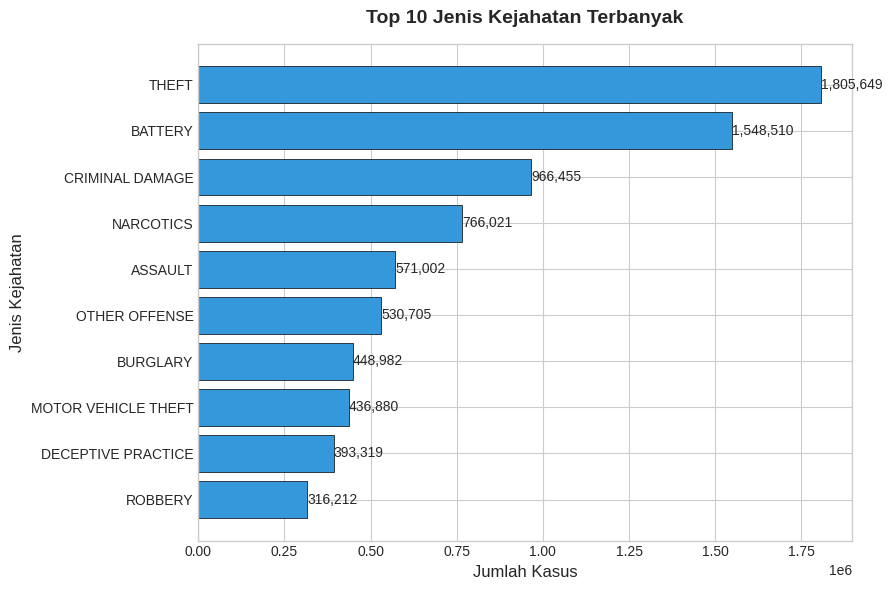

In [8]:
# Top 10 Jenis Kejahatan
fig, ax = plt.subplots(figsize=(9, 6))

top_crimes = df['Primary Type'].value_counts().head(10)

ax.barh(
    top_crimes.index[::-1],
    top_crimes.values[::-1],
    color='#3498DB',
    edgecolor='black',
    linewidth=0.5
)

for i, val in enumerate(top_crimes.values[::-1]):
    ax.text(val + 10, i, f'{val:,}', va='center', fontsize=10)

ax.set_title('Top 10 Jenis Kejahatan Terbanyak', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Jumlah Kasus', fontsize=12)
ax.set_ylabel('Jenis Kejahatan', fontsize=12)

plt.tight_layout()
plt.savefig('plot2_top10_kejahatan.png', dpi=150, bbox_inches='tight')
plt.show()

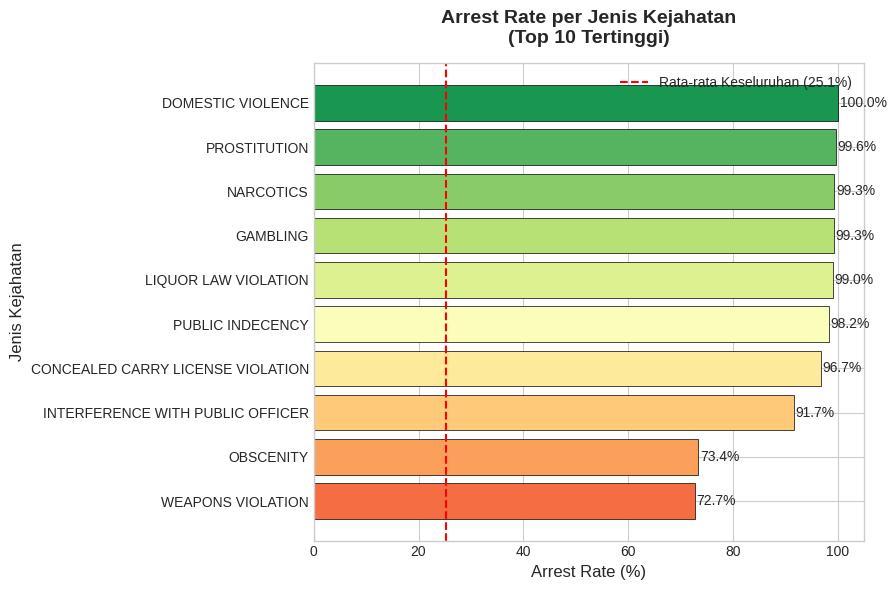

In [9]:
# Arrest Rate per Jenis Kejahatan (Top 10)
fig, ax = plt.subplots(figsize=(9, 6))

arrest_by_type = (
    df.groupby('Primary Type')['Arrest']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

colors_rate = plt.cm.RdYlGn(np.linspace(0.2, 0.9, len(arrest_by_type)))

ax.barh(
    arrest_by_type.index[::-1],
    arrest_by_type.values[::-1] * 100,
    color=colors_rate,
    edgecolor='black',
    linewidth=0.5
)

for i, val in enumerate(arrest_by_type.values[::-1]):
    ax.text(val * 100 + 0.3, i, f'{val * 100:.1f}%', va='center', fontsize=10)

ax.set_title('Arrest Rate per Jenis Kejahatan\n(Top 10 Tertinggi)', 
             fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Arrest Rate (%)', fontsize=12)
ax.set_ylabel('Jenis Kejahatan', fontsize=12)
ax.axvline(
    x=df['Arrest'].mean() * 100,
    color='red', linestyle='--', linewidth=1.5,
    label=f'Rata-rata Keseluruhan ({df["Arrest"].mean() * 100:.1f}%)'
)
ax.legend(fontsize=10)

plt.tight_layout()
plt.savefig('plot3_arrest_rate_per_kejahatan.png', dpi=150, bbox_inches='tight')
plt.show()

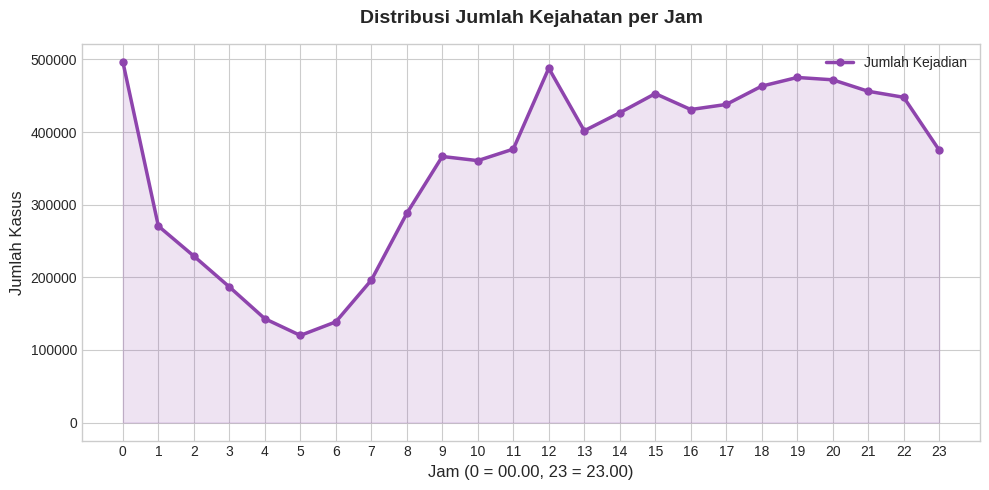

In [10]:
# Distribusi Kejahatan per Jam
fig, ax = plt.subplots(figsize=(10, 5))

# Pastikan kolom Hour sudah ada
df['Hour'] = pd.to_datetime(df['Date'], errors='coerce').dt.hour
hour_stats = df.groupby('Hour')['Arrest'].agg(['count', 'mean'])

ax.plot(
    hour_stats.index,
    hour_stats['count'],
    color='#8E44AD',
    linewidth=2.5,
    marker='o',
    markersize=5,
    label='Jumlah Kejadian'
)
ax.fill_between(hour_stats.index, hour_stats['count'], alpha=0.15, color='#8E44AD')

ax.set_title('Distribusi Jumlah Kejahatan per Jam', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Jam (0 = 00.00, 23 = 23.00)', fontsize=12)
ax.set_ylabel('Jumlah Kasus', fontsize=12)
ax.set_xticks(range(0, 24))
ax.legend(fontsize=10)

plt.tight_layout()
plt.savefig('plot4_kejahatan_per_jam.png', dpi=150, bbox_inches='tight')
plt.show()

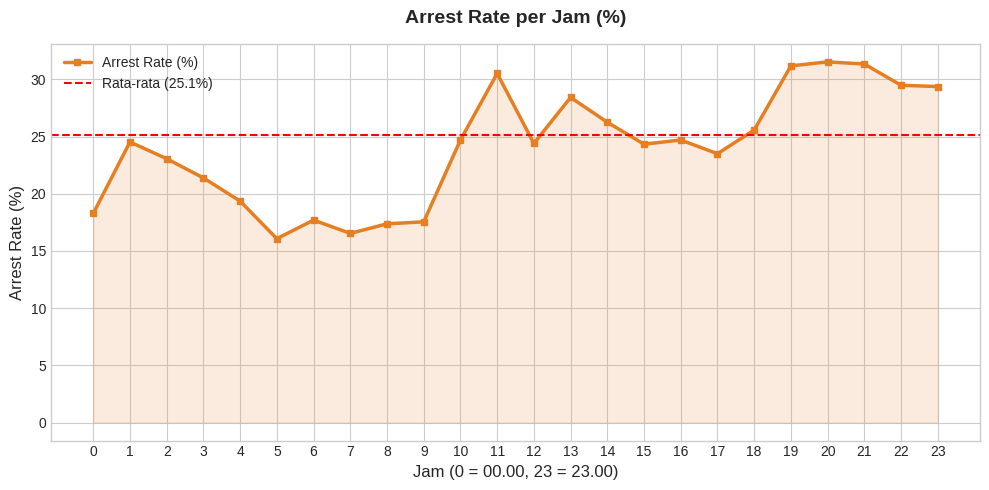

In [11]:
# Arrest Rate per Jam
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    hour_stats.index,
    hour_stats['mean'] * 100,
    color='#E67E22',
    linewidth=2.5,
    marker='s',
    markersize=5,
    label='Arrest Rate (%)'
)
ax.fill_between(hour_stats.index, hour_stats['mean'] * 100, alpha=0.15, color='#E67E22')

# Garis rata-rata
avg_arrest_rate = df['Arrest'].mean() * 100
ax.axhline(
    y=avg_arrest_rate,
    color='red', linestyle='--', linewidth=1.5,
    label=f'Rata-rata ({avg_arrest_rate:.1f}%)'
)

ax.set_title('Arrest Rate per Jam (%)', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Jam (0 = 00.00, 23 = 23.00)', fontsize=12)
ax.set_ylabel('Arrest Rate (%)', fontsize=12)
ax.set_xticks(range(0, 24))
ax.legend(fontsize=10)

plt.tight_layout()
plt.savefig('plot5_arrest_rate_per_jam.png', dpi=150, bbox_inches='tight')
plt.show()

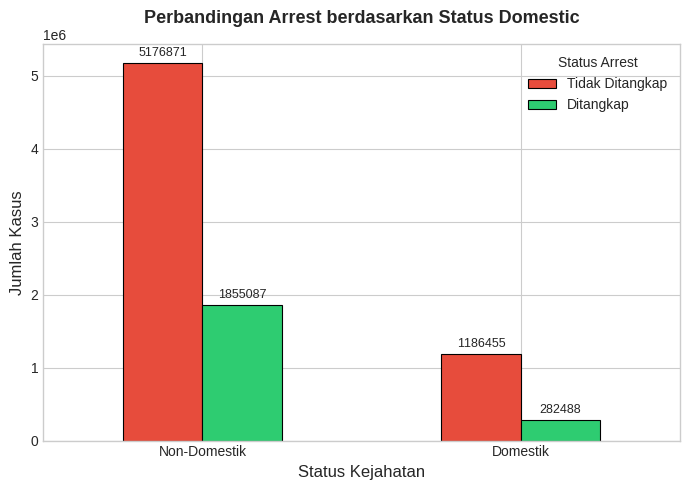

In [12]:
# Arrest per Domestic Status
fig, ax = plt.subplots(figsize=(7, 5))

domestic_arrest = (
    df.groupby('Domestic')['Arrest']
    .value_counts()
    .unstack()
    .fillna(0)
)
domestic_arrest.index = ['Non-Domestik', 'Domestik']
domestic_arrest.columns = ['Tidak Ditangkap', 'Ditangkap']

domestic_arrest.plot(
    kind='bar',
    ax=ax,
    color=['#E74C3C', '#2ECC71'],
    edgecolor='black',
    linewidth=0.8,
    width=0.5
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', fontsize=9, padding=3)

ax.set_title('Perbandingan Arrest berdasarkan Status Domestic', 
             fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Status Kejahatan', fontsize=12)
ax.set_ylabel('Jumlah Kasus', fontsize=12)
ax.set_xticklabels(['Non-Domestik', 'Domestik'], rotation=0)
ax.legend(title='Status Arrest', fontsize=10)

plt.tight_layout()
plt.savefig('plot6_arrest_vs_domestic.png', dpi=150, bbox_inches='tight')
plt.show()

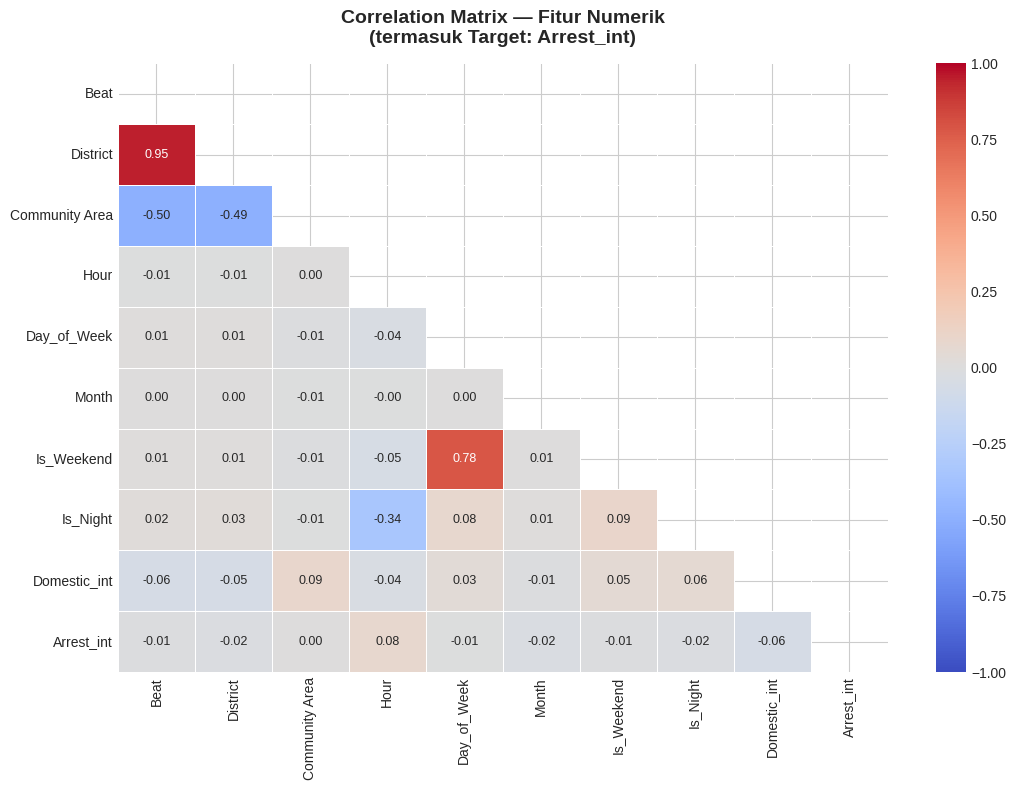

Correlation Matrix Numerik

📌 Interpretasi:
   • Nilai mendekati  1 → korelasi positif kuat
   • Nilai mendekati -1 → korelasi negatif kuat
   • Nilai mendekati  0 → tidak ada korelasi


In [13]:
# Correlation Matrix

df['Hour']        = pd.to_datetime(df['Date'], errors='coerce').dt.hour
df['Day_of_Week'] = pd.to_datetime(df['Date'], errors='coerce').dt.dayofweek
df['Month']       = pd.to_datetime(df['Date'], errors='coerce').dt.month
df['Is_Weekend']  = df['Day_of_Week'].isin([5, 6]).astype(int)
df['Is_Night']    = df['Hour'].apply(lambda x: 1 if (x >= 22 or x <= 5) else 0)
df['Arrest_int']  = df['Arrest'].astype(int)
df['Domestic_int']= df['Domestic'].astype(int)

# Pilih kolom numerik saja
NUMERIK = [
    'Beat', 'District', 'Community Area',
    'Hour', 'Day_of_Week', 'Month',
    'Is_Weekend', 'Is_Night',
    'Domestic_int', 'Arrest_int'
]

corr_matrix = df[NUMERIK].corr()

fig, ax = plt.subplots(figsize=(11, 8))

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))  

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1, vmax=1,
    linewidths=0.5,
    linecolor='white',
    ax=ax,
    annot_kws={'size': 9}
)

ax.set_title('Correlation Matrix — Fitur Numerik\n(termasuk Target: Arrest_int)', 
             fontsize=14, fontweight='bold', pad=15)

plt.tight_layout()
plt.savefig('plot7_correlation_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print("Correlation Matrix Numerik")
print("\n📌 Interpretasi:")
print("   • Nilai mendekati  1 → korelasi positif kuat")
print("   • Nilai mendekati -1 → korelasi negatif kuat")
print("   • Nilai mendekati  0 → tidak ada korelasi")

📊 Menghitung Cramér's V untuk fitur kategorikal vs Arrest...
   Primary Type                   → Cramér's V = 0.6562
   Location Description           → Cramér's V = 0.3009
   Domestic                       → Cramér's V = 0.0623


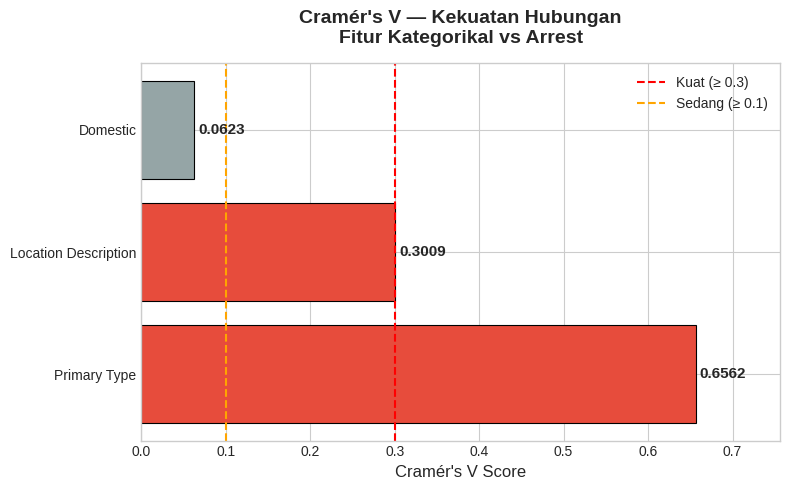


Interpretasi Cramér's V:
   • ≥ 0.3 → Hubungan KUAT   → fitur penting, masukkan ke model
   • 0.1–0.3 → Hubungan SEDANG → pertimbangkan untuk dimasukkan
   • < 0.1 → Hubungan LEMAH  → pertimbangkan untuk dibuang


In [14]:
# Cramér's V — Fitur Kategorikal vs Target (Arrest)

from scipy.stats import chi2_contingency

def cramers_v(col1, col2):
    """Hitung Cramér's V antara dua kolom kategorikal."""
    confusion_table = pd.crosstab(col1, col2)
    chi2 = chi2_contingency(confusion_table)[0]
    n    = confusion_table.sum().sum()
    r, k = confusion_table.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

# Kolom kategorikal yang ingin diuji
KATEGORIK = ['Primary Type', 'Location Description', 'Domestic']

print("📊 Menghitung Cramér's V untuk fitur kategorikal vs Arrest...")
cramers_scores = {}
for col in KATEGORIK:
    score = cramers_v(df[col].astype(str), df['Arrest'].astype(str))
    cramers_scores[col] = round(score, 4)
    print(f"   {col:30s} → Cramér's V = {score:.4f}")

# Visualisasi
fig, ax = plt.subplots(figsize=(8, 5))

cols   = list(cramers_scores.keys())
values = list(cramers_scores.values())
colors_cv = ['#E74C3C' if v >= 0.3 else '#F39C12' if v >= 0.1 else '#95A5A6' for v in values]

bars = ax.barh(cols, values, color=colors_cv, edgecolor='black', linewidth=0.8)

for bar, val in zip(bars, values):
    ax.text(val + 0.005, bar.get_y() + bar.get_height() / 2,
            f'{val:.4f}', va='center', fontsize=11, fontweight='bold')

# Garis referensi
ax.axvline(x=0.3, color='red',    linestyle='--', linewidth=1.5, label='Kuat (≥ 0.3)')
ax.axvline(x=0.1, color='orange', linestyle='--', linewidth=1.5, label='Sedang (≥ 0.1)')

ax.set_title("Cramér's V — Kekuatan Hubungan\nFitur Kategorikal vs Arrest", 
             fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Cramér's V Score", fontsize=12)
ax.set_xlim(0, max(values) + 0.1)
ax.legend(fontsize=10)

plt.tight_layout()
plt.savefig('plot8_cramers_v.png', dpi=150, bbox_inches='tight')
plt.show()
print("\nInterpretasi Cramér's V:")
print("   • ≥ 0.3 → Hubungan KUAT   → fitur penting, masukkan ke model")
print("   • 0.1–0.3 → Hubungan SEDANG → pertimbangkan untuk dimasukkan")
print("   • < 0.1 → Hubungan LEMAH  → pertimbangkan untuk dibuang")

📊 Menghitung Point Biserial Correlation vs Arrest...
   Beat                 → r = -0.0131 | p-value = 0.0000 | ✅ Signifikan
   District             → r = -0.0164 | p-value = 0.0000 | ✅ Signifikan
   Community Area       → r = +0.0006 | p-value = 0.1191 | ❌ Tidak Signifikan
   Hour                 → r = +0.0813 | p-value = 0.0000 | ✅ Signifikan
   Day_of_Week          → r = -0.0051 | p-value = 0.0000 | ✅ Signifikan
   Month                → r = -0.0236 | p-value = 0.0000 | ✅ Signifikan
   Is_Weekend           → r = -0.0092 | p-value = 0.0000 | ✅ Signifikan
   Is_Night             → r = -0.0193 | p-value = 0.0000 | ✅ Signifikan
   Domestic_int         → r = -0.0623 | p-value = 0.0000 | ✅ Signifikan


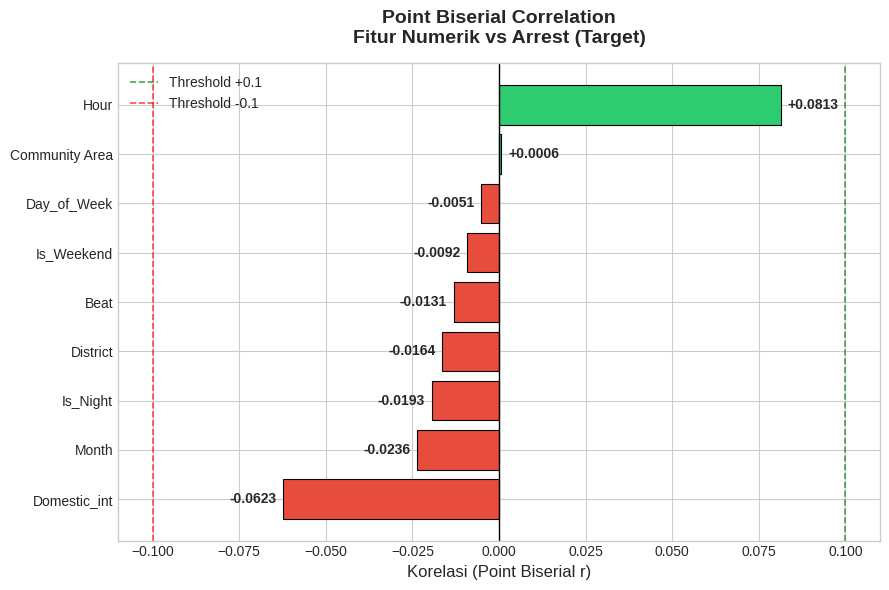


📌 Interpretasi Point Biserial:
   • r > +0.1 → Korelasi positif dengan Arrest → fitur relevan
   • r < -0.1 → Korelasi negatif dengan Arrest → fitur relevan
   • |r| < 0.1 → Korelasi lemah → pertimbangkan dibuang


In [15]:
# Point Biserial Correlation — Fitur Numerik vs Arrest

from scipy.stats import pointbiserialr

NUMERIK_FITUR = [
    'Beat', 'District', 'Community Area',
    'Hour', 'Day_of_Week', 'Month',
    'Is_Weekend', 'Is_Night', 'Domestic_int'
]

print("📊 Menghitung Point Biserial Correlation vs Arrest...")
pb_scores = {}
for col in NUMERIK_FITUR:
    temp = df[[col, 'Arrest_int']].dropna()
    corr, pval = pointbiserialr(temp[col], temp['Arrest_int'])
    pb_scores[col] = {'correlation': round(corr, 4), 'p_value': round(pval, 4)}
    signifikan = "✅ Signifikan" if pval < 0.05 else "❌ Tidak Signifikan"
    print(f"   {col:20s} → r = {corr:+.4f} | p-value = {pval:.4f} | {signifikan}")

# Visualisasi
fig, ax = plt.subplots(figsize=(9, 6))

pb_df = pd.DataFrame(pb_scores).T.sort_values('correlation')
colors_pb = ['#E74C3C' if v < 0 else '#2ECC71' for v in pb_df['correlation']]

bars = ax.barh(
    pb_df.index,
    pb_df['correlation'],
    color=colors_pb,
    edgecolor='black',
    linewidth=0.8
)

for bar, val in zip(bars, pb_df['correlation']):
    x_pos = val + 0.002 if val >= 0 else val - 0.002
    ha    = 'left' if val >= 0 else 'right'
    ax.text(x_pos, bar.get_y() + bar.get_height() / 2,
            f'{val:+.4f}', va='center', ha=ha, fontsize=10, fontweight='bold')

ax.axvline(x=0,    color='black', linewidth=1)
ax.axvline(x=0.1,  color='green',  linestyle='--', linewidth=1.2, alpha=0.7, label='Threshold +0.1')
ax.axvline(x=-0.1, color='red',    linestyle='--', linewidth=1.2, alpha=0.7, label='Threshold -0.1')

ax.set_title('Point Biserial Correlation\nFitur Numerik vs Arrest (Target)', 
             fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Korelasi (Point Biserial r)', fontsize=12)
ax.legend(fontsize=10)

plt.tight_layout()
plt.savefig('plot9_point_biserial.png', dpi=150, bbox_inches='tight')
plt.show()
print("\n📌 Interpretasi Point Biserial:")
print("   • r > +0.1 → Korelasi positif dengan Arrest → fitur relevan")
print("   • r < -0.1 → Korelasi negatif dengan Arrest → fitur relevan")
print("   • |r| < 0.1 → Korelasi lemah → pertimbangkan dibuang")

# **Data Preparation**

In [16]:
df_clean = df.copy()
df_clean

,ID,Case Number,Date,Block,IUCR,Primary Type,Description,Location Description,Arrest,Domestic,...,Latitude,Longitude,Location,Hour,Day_of_Week,Month,Is_Weekend,Is_Night,Arrest_int,Domestic_int
0,13311263,JG503434,07/29/2022 03:39:00 AM,023XX S TROY ST,1582,OFFENSE INVOLVING CHILDREN,CHILD PORNOGRAPHY,RESIDENCE,True,False,...,NaN,NaN,NaN,3,4,7,0,1,1,0
1,13053066,JG103252,01/03/2023 04:44:00 PM,039XX W WASHINGTON BLVD,2017,NARCOTICS,MANUFACTURE / DELIVER - CRACK,SIDEWALK,True,False,...,NaN,NaN,NaN,16,1,1,0,0,1,0
2,12131221,JD327000,08/10/2020 09:45:00 AM,015XX N DAMEN AVE,0326,ROBBERY,AGGRAVATED VEHICULAR HIJACKING,STREET,True,False,...,41.908418,-87.677407,"(41.908417822, -87.67740693)",9,0,8,0,0,1,0
3,11227634,JB147599,08/26/2017 10:00:00 AM,001XX W RANDOLPH ST,0281,CRIM SEXUAL ASSAULT,NON-AGGRAVATED,HOTEL/MOTEL,False,False,...,NaN,NaN,NaN,10,5,8,1,0,0,0
4,13203321,JG415333,09/06/2023 05:00:00 PM,002XX N Wells st,1320,CRIMINAL DAMAGE,TO VEHICLE,PARKING LOT / GARAGE (NON RESIDENTIAL),False,False,...,41.886018,-87.633938,"(41.886018055, -87.633937881)",17,2,9,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8500896,14012613,JJ463710,10/16/2025 01:28:00 PM,015XX S KENNETH AVE,1752,OFFENSE INVOLVING CHILDREN,AGGRAVATED CRIMINAL SEXUAL ABUSE BY FAMILY MEMBER,RESIDENCE,False,True,...,41.859709,-87.735986,"(41.859708775, -87.735986352)",13,3,10,0,0,0,1
8500897,14011813,JJ468463,10/18/2025 11:30:00 AM,102XX W ZEMKE RD,1206,DECEPTIVE PRACTICE,"THEFT BY LESSEE, MOTOR VEHICLE",AIRPORT BUILDING NON-TERMINAL - NON-SECURE AREA,False,False,...,41.995002,-87.881915,"(41.995001671, -87.881914976)",11,5,10,1,0,0,0
8500898,14001853,JJ456646,10/18/2025 05:34:00 PM,016XX S ASHLAND AVE,0810,THEFT,OVER $500,APARTMENT,False,False,...,41.859270,-87.666192,"(41.859269673, -87.666191925)",17,5,10,1,0,0,0
8500899,14006760,JJ462617,10/23/2025 03:54:00 PM,032XX N CLARK ST,1330,CRIMINAL TRESPASS,TO LAND,DEPARTMENT STORE,False,False,...,41.940449,-87.651082,"(41.94044868, -87.651081589)",15,3,10,0,0,0,0


In [17]:
# Cek jumlah duplikat
jumlah_duplikat = df_clean.duplicated().sum()
pct_duplikat    = jumlah_duplikat / len(df_clean) * 100

print(f"\n📊 Total baris         : {len(df_clean):,}")
print(f"🔁 Baris duplikat      : {jumlah_duplikat:,} ({pct_duplikat:.4f}%)")
print(f"✅ Baris unik          : {len(df_clean) - jumlah_duplikat:,}")


📊 Total baris         : 8,500,901
🔁 Baris duplikat      : 0 (0.0000%)
✅ Baris unik          : 8,500,901


In [18]:
if jumlah_duplikat > 0:
    print("📋 Contoh baris yang terduplikasi:")
    duplikat_df = df_clean[df_clean.duplicated(keep=False)].sort_values(by=df_clean.columns.tolist())
    print(duplikat_df.head(10))

    print(f"\n⚠️  Ditemukan {jumlah_duplikat:,} duplikat → akan dihapus")
    
    # Hapus duplikat
    sebelum     = len(df_clean)
    df_clean    = df_clean.drop_duplicates()
    sesudah     = len(df_clean)
    
    print(f"\n🧹 Drop duplikat:")
    print(f"   Sebelum : {sebelum:,} baris")
    print(f"   Sesudah : {sesudah:,} baris")
    print(f"   Dihapus : {sebelum - sesudah:,} baris")
    print(f"   ✅ Data bersih dari duplikat!")

else:
    print("✅ Tidak ada data duplikat! Dataset sudah bersih.")

✅ Tidak ada data duplikat! Dataset sudah bersih.


In [19]:
# Ekstraksi fitur waktu dari kolom Date

df_clean['Date'] = pd.to_datetime(df_clean['Date'], errors='coerce')
df_clean['Hour'] = df_clean['Date'].dt.hour

df_clean

,ID,Case Number,Date,Block,IUCR,Primary Type,Description,Location Description,Arrest,Domestic,...,Latitude,Longitude,Location,Hour,Day_of_Week,Month,Is_Weekend,Is_Night,Arrest_int,Domestic_int
0,13311263,JG503434,2022-07-29 03:39:00,023XX S TROY ST,1582,OFFENSE INVOLVING CHILDREN,CHILD PORNOGRAPHY,RESIDENCE,True,False,...,NaN,NaN,NaN,3,4,7,0,1,1,0
1,13053066,JG103252,2023-01-03 16:44:00,039XX W WASHINGTON BLVD,2017,NARCOTICS,MANUFACTURE / DELIVER - CRACK,SIDEWALK,True,False,...,NaN,NaN,NaN,16,1,1,0,0,1,0
2,12131221,JD327000,2020-08-10 09:45:00,015XX N DAMEN AVE,0326,ROBBERY,AGGRAVATED VEHICULAR HIJACKING,STREET,True,False,...,41.908418,-87.677407,"(41.908417822, -87.67740693)",9,0,8,0,0,1,0
3,11227634,JB147599,2017-08-26 10:00:00,001XX W RANDOLPH ST,0281,CRIM SEXUAL ASSAULT,NON-AGGRAVATED,HOTEL/MOTEL,False,False,...,NaN,NaN,NaN,10,5,8,1,0,0,0
4,13203321,JG415333,2023-09-06 17:00:00,002XX N Wells st,1320,CRIMINAL DAMAGE,TO VEHICLE,PARKING LOT / GARAGE (NON RESIDENTIAL),False,False,...,41.886018,-87.633938,"(41.886018055, -87.633937881)",17,2,9,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8500896,14012613,JJ463710,2025-10-16 13:28:00,015XX S KENNETH AVE,1752,OFFENSE INVOLVING CHILDREN,AGGRAVATED CRIMINAL SEXUAL ABUSE BY FAMILY MEMBER,RESIDENCE,False,True,...,41.859709,-87.735986,"(41.859708775, -87.735986352)",13,3,10,0,0,0,1
8500897,14011813,JJ468463,2025-10-18 11:30:00,102XX W ZEMKE RD,1206,DECEPTIVE PRACTICE,"THEFT BY LESSEE, MOTOR VEHICLE",AIRPORT BUILDING NON-TERMINAL - NON-SECURE AREA,False,False,...,41.995002,-87.881915,"(41.995001671, -87.881914976)",11,5,10,1,0,0,0
8500898,14001853,JJ456646,2025-10-18 17:34:00,016XX S ASHLAND AVE,0810,THEFT,OVER $500,APARTMENT,False,False,...,41.859270,-87.666192,"(41.859269673, -87.666191925)",17,5,10,1,0,0,0
8500899,14006760,JJ462617,2025-10-23 15:54:00,032XX N CLARK ST,1330,CRIMINAL TRESPASS,TO LAND,DEPARTMENT STORE,False,False,...,41.940449,-87.651082,"(41.94044868, -87.651081589)",15,3,10,0,0,0,0


In [20]:
print(f"\n📊 Distribusi Hour (sample):")
print(df_clean['Hour'].describe())


📊 Distribusi Hour (sample):
count    8.500901e+06
mean     1.306652e+01
std      6.761487e+00
min      0.000000e+00
25%      9.000000e+00
50%      1.400000e+01
75%      1.900000e+01
max      2.300000e+01
Name: Hour, dtype: float64


In [21]:
# Seleksi Fitur Final Berdasarkan Analisis


# Fitur yang masuk berdasarkan Cramér's V + Point Biserial + Correlation Matrix
FITUR = [
    'Primary Type',         
    'Location Description', 
    'Hour',                
    'District',             
    'Domestic',             
]

TARGET = 'Arrest'

print(f"\nFitur yang DIPAKAI ({len(FITUR)} fitur):")
for f in FITUR:
    print(f"   → {f}")


# Subset dataframe
df_model = df_clean[FITUR + [TARGET]].copy()
df_model


Fitur yang DIPAKAI (5 fitur):
   → Primary Type
   → Location Description
   → Hour
   → District
   → Domestic


,Primary Type,Location Description,Hour,District,Domestic,Arrest
0,OFFENSE INVOLVING CHILDREN,RESIDENCE,3,10.0,False,True
1,NARCOTICS,SIDEWALK,16,11.0,False,True
2,ROBBERY,STREET,9,14.0,False,True
3,CRIM SEXUAL ASSAULT,HOTEL/MOTEL,10,1.0,False,False
4,CRIMINAL DAMAGE,PARKING LOT / GARAGE (NON RESIDENTIAL),17,1.0,False,False
...,...,...,...,...,...,...
8500896,OFFENSE INVOLVING CHILDREN,RESIDENCE,13,10.0,True,False
8500897,DECEPTIVE PRACTICE,AIRPORT BUILDING NON-TERMINAL - NON-SECURE AREA,11,16.0,False,False
8500898,THEFT,APARTMENT,17,12.0,False,False
8500899,CRIMINAL TRESPASS,DEPARTMENT STORE,15,19.0,False,False


In [22]:
# Handle Missing Values

print("Cek missing values pada fitur yang dipilih...")

missing = df_model.isnull().sum()
missing_pct = (missing / len(df_model) * 100).round(2)
missing_df = pd.DataFrame({
    'Missing Count': missing, 
    'Missing %': missing_pct
})

missing_df

Cek missing values pada fitur yang dipilih...


,Missing Count,Missing %
Primary Type,0,0.00
Location Description,15626,0.18
Hour,0,0.00
District,47,0.00
Domestic,0,0.00
Arrest,0,0.00


In [23]:
# Drop baris dengan missing values
sebelum = len(df_model)
df_model.dropna(inplace=True)
sesudah = len(df_model)

print(f"\nDrop missing values:")
print(f"   Sebelum : {sebelum:,} baris")
print(f"   Sesudah : {sesudah:,} baris")
print(f"   Dihapus : {sebelum - sesudah:,} baris ({(sebelum-sesudah)/sebelum*100:.2f}%)")


Drop missing values:
   Sebelum : 8,500,901 baris
   Sesudah : 8,485,228 baris
   Dihapus : 15,673 baris (0.18%)


In [24]:
print("Cek missing values pada fitur yang dipilih...")

missing = df_model.isnull().sum()
missing_pct = (missing / len(df_model) * 100).round(2)
missing_df = pd.DataFrame({
    'Missing Count': missing, 
    'Missing %': missing_pct
})

missing_df

Cek missing values pada fitur yang dipilih...


,Missing Count,Missing %
Primary Type,0,0.0
Location Description,0,0.0
Hour,0,0.0
District,0,0.0
Domestic,0,0.0
Arrest,0,0.0


In [25]:
# Encoding Fitur Kategorikal

from sklearn.preprocessing import LabelEncoder

# Inisialisasi encoder (disimpan untuk deployment nanti)
le_primary_type  = LabelEncoder()
le_location_desc = LabelEncoder()

# Encoding
df_model['Primary Type']         = le_primary_type.fit_transform(df_model['Primary Type'].astype(str))
df_model['Location Description'] = le_location_desc.fit_transform(df_model['Location Description'].astype(str))
df_model['Domestic']             = df_model['Domestic'].astype(int)
df_model[TARGET]                 = df_model[TARGET].astype(int)

print("   Primary Type      → Label Encoded")
print("   Location Description → Label Encoded")
print("   Domestic          → Converted to int (True=1, False=0)")
print("   Arrest (Target)   → Converted to int (True=1, False=0)")

# Cek mapping Primary Type
print(f"\nContoh mapping Primary Type:")
mapping_sample = dict(zip(
    le_primary_type.classes_[:5], 
    le_primary_type.transform(le_primary_type.classes_[:5])
))
for k, v in mapping_sample.items():
    print(f"   '{k}' → {v}")

print(f"\nPreview data setelah encoding:")
df_model

   Primary Type      → Label Encoded
   Location Description → Label Encoded
   Domestic          → Converted to int (True=1, False=0)
   Arrest (Target)   → Converted to int (True=1, False=0)

Contoh mapping Primary Type:
   'ARSON' → 0
   'ASSAULT' → 1
   'BATTERY' → 2
   'BURGLARY' → 3
   'CONCEALED CARRY LICENSE VIOLATION' → 4

Preview data setelah encoding:


,Primary Type,Location Description,Hour,District,Domestic,Arrest
0,22,161,3,10.0,0,1
1,19,185,16,11.0,0,1
2,29,190,9,14.0,0,1
3,5,116,10,1.0,0,0
4,6,148,17,1.0,0,0
...,...,...,...,...,...,...
8500896,22,161,13,10.0,1,0
8500897,9,2,11,16.0,0,0
8500898,32,17,17,12.0,0,0
8500899,8,83,15,19.0,0,0


In [26]:
# Sampling (agar SVM tidak terlalu lambat)

print(f"   Dataset asli : {len(df_model):,} baris")
print(f"   ⚠️  SVM memiliki kompleksitas O(n²) hingga O(n³)")
print(f"   → Dataset besar akan membuat training sangat lambat")

SAMPLE_SIZE = 15000

df_model = df_model.sample(n=min(SAMPLE_SIZE, len(df_model)), random_state=42)

print(f"\n   ✅ Dataset setelah sampling: {len(df_model):,} baris")
print(f"   (Sample diambil secara random dengan random_state=42 untuk reproducibility)")

   Dataset asli : 8,485,228 baris
   ⚠️  SVM memiliki kompleksitas O(n²) hingga O(n³)
   → Dataset besar akan membuat training sangat lambat

   ✅ Dataset setelah sampling: 15,000 baris
   (Sample diambil secara random dengan random_state=42 untuk reproducibility)


In [27]:
# Handle Class Imbalance

from sklearn.utils import resample

print("Cek distribusi kelas target (Arrest)...")

class_counts = df_model[TARGET].value_counts()
print(f"\n   Kelas 0 (Tidak Ditangkap) : {class_counts[0]:,} ({class_counts[0]/len(df_model)*100:.1f}%)")
print(f"   Kelas 1 (Ditangkap)        : {class_counts[1]:,} ({class_counts[1]/len(df_model)*100:.1f}%)")

imbalance_ratio = class_counts[0] / class_counts[1]
print(f"\n   Rasio imbalance            : {imbalance_ratio:.1f}:1")

if imbalance_ratio > 1.5:
    print(f"   Dataset IMBALANCED → perlu penanganan!")
    
    # Undersampling majority class
    df_majority  = df_model[df_model[TARGET] == 0]
    df_minority  = df_model[df_model[TARGET] == 1]
    
    df_majority_down = resample(
        df_majority,
        replace=False,
        n_samples=len(df_minority),
        random_state=42
    )
    
    df_balanced = pd.concat([df_majority_down, df_minority]).sample(frac=1, random_state=42)
    
    print(f"\n   ✅ Setelah Undersampling:")
    print(f"   Kelas 0 : {df_balanced[TARGET].value_counts()[0]:,}")
    print(f"   Kelas 1 : {df_balanced[TARGET].value_counts()[1]:,}")
    print(f"   Total   : {len(df_balanced):,} baris (50:50)")
else:
    df_balanced = df_model.copy()
    print("   ✅ Dataset sudah cukup seimbang, tidak perlu undersampling")

Cek distribusi kelas target (Arrest)...

   Kelas 0 (Tidak Ditangkap) : 11,221 (74.8%)
   Kelas 1 (Ditangkap)        : 3,779 (25.2%)

   Rasio imbalance            : 3.0:1
   Dataset IMBALANCED → perlu penanganan!

   ✅ Setelah Undersampling:
   Kelas 0 : 3,779
   Kelas 1 : 3,779
   Total   : 7,558 baris (50:50)


In [28]:
# Train-Test Split

from sklearn.model_selection import train_test_split

X = df_balanced[FITUR]
y = df_balanced[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y       # pastikan proporsi kelas sama di train & test
)

print(f"\n   Total data    : {len(df_balanced):,} baris")
print(f"   Training set  : {X_train.shape[0]:,} baris (80%)")
print(f"   Testing set   : {X_test.shape[0]:,} baris (20%)")

print(f"\n   Distribusi kelas di Training set:")
print(f"   Kelas 0 : {(y_train==0).sum():,} | Kelas 1 : {(y_train==1).sum():,}")
print(f"\n   Distribusi kelas di Testing set:")
print(f"   Kelas 0 : {(y_test==0).sum():,} | Kelas 1 : {(y_test==1).sum():,}")


   Total data    : 7,558 baris
   Training set  : 6,046 baris (80%)
   Testing set   : 1,512 baris (20%)

   Distribusi kelas di Training set:
   Kelas 0 : 3,023 | Kelas 1 : 3,023

   Distribusi kelas di Testing set:
   Kelas 0 : 756 | Kelas 1 : 756


# **Modelling (SVM)**

In [29]:
svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', 
                C=10, 
                gamma='scale', 
                class_weight='balanced',
                probability=True,
                random_state=42))
])

In [30]:
# Training model

print("Training model SVM... ")
svm_pipeline.fit(X_train, y_train)
print("Training selesai!")

Training model SVM... 
Training selesai!


In [31]:
# Prediksi
y_pred      = svm_pipeline.predict(X_test)
y_pred_prob = svm_pipeline.predict_proba(X_test)[:, 1]

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, 
      target_names=['Tidak Ditangkap (0)', 'Ditangkap (1)']))


Classification Report:
                     precision    recall  f1-score   support

Tidak Ditangkap (0)       0.65      0.81      0.72       756
      Ditangkap (1)       0.75      0.57      0.65       756

           accuracy                           0.69      1512
          macro avg       0.70      0.69      0.68      1512
       weighted avg       0.70      0.69      0.68      1512



In [32]:
# Hyperparameter Tuning dengan GridSearchCV
print("\n🔍 Hyperparameter Tuning dengan GridSearchCV...")
param_grid = {
    'svm__C'      : [0.1, 1, 10],  # lebih lebar
    'svm__kernel' : ['linear', 'rbf', 'poly'],  # tambah poly
    'svm__gamma'  : ['scale', 'auto', 0.01, 0.1]
}

grid_search = GridSearchCV(
    Pipeline([('scaler', StandardScaler()),
              ('svm', SVC(class_weight='balanced', probability=True, random_state=42))]),
    param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)
grid_search.fit(X_train, y_train)


🔍 Hyperparameter Tuning dengan GridSearchCV...
Fitting 5 folds for each of 36 candidates, totalling 180 fits


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('svm',
                                        SVC(class_weight='balanced',
                                            probability=True,
                                            random_state=42))]),
             n_jobs=-1,
             param_grid={'svm__C': [0.1, 1, 10],
                         'svm__gamma': ['scale', 'auto', 0.01, 0.1],
                         'svm__kernel': ['linear', 'rbf', 'poly']},
             scoring='f1', verbose=1)

In [33]:
print(f"\nParameter terbaik  : {grid_search.best_params_}")
print(f"F1-Score terbaik   : {grid_search.best_score_:.4f}")

# Gunakan model terbaik
best_model = grid_search.best_estimator_


Parameter terbaik  : {'svm__C': 1, 'svm__gamma': 0.1, 'svm__kernel': 'rbf'}
F1-Score terbaik   : 0.6491


# **Evaluasi**

In [34]:
# Prediksi
y_pred      = best_model.predict(X_test)
y_pred_prob = best_model.predict_proba(X_test)[:, 1]

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, 
      target_names=['Tidak Ditangkap (0)', 'Ditangkap (1)']))


Classification Report:
                     precision    recall  f1-score   support

Tidak Ditangkap (0)       0.65      0.83      0.73       756
      Ditangkap (1)       0.77      0.55      0.64       756

           accuracy                           0.69      1512
          macro avg       0.71      0.69      0.68      1512
       weighted avg       0.71      0.69      0.68      1512



In [35]:
# Metrik utama

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy  = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall    = recall_score(y_test, y_pred)
f1        = f1_score(y_test, y_pred)
auc       = roc_auc_score(y_test, y_pred_prob)

print(f"\nRingkasan Metrik:")
print(f"   Accuracy  : {accuracy:.4f}  ({accuracy*100:.2f}%)")
print(f"   Precision : {precision:.4f}")
print(f"   Recall    : {recall:.4f}")
print(f"   F1-Score  : {f1:.4f}")
print(f"   ROC-AUC   : {auc:.4f}")


Ringkasan Metrik:
   Accuracy  : 0.6898  (68.98%)
   Precision : 0.7662
   Recall    : 0.5463
   F1-Score  : 0.6378
   ROC-AUC   : 0.6995


In [36]:
# Cross-Validation
print("\nCross-Validation (5-Fold):")
cv_scores = cross_val_score(best_model, X_train, y_train, cv=5, scoring='f1', n_jobs=-1)
print(f"   F1 tiap fold : {[f'{s:.4f}' for s in cv_scores]}")
print(f"   F1 rata-rata : {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")


Cross-Validation (5-Fold):
   F1 tiap fold : ['0.6589', '0.6324', '0.6590', '0.6395', '0.6559']
   F1 rata-rata : 0.6491 (+/- 0.0110)


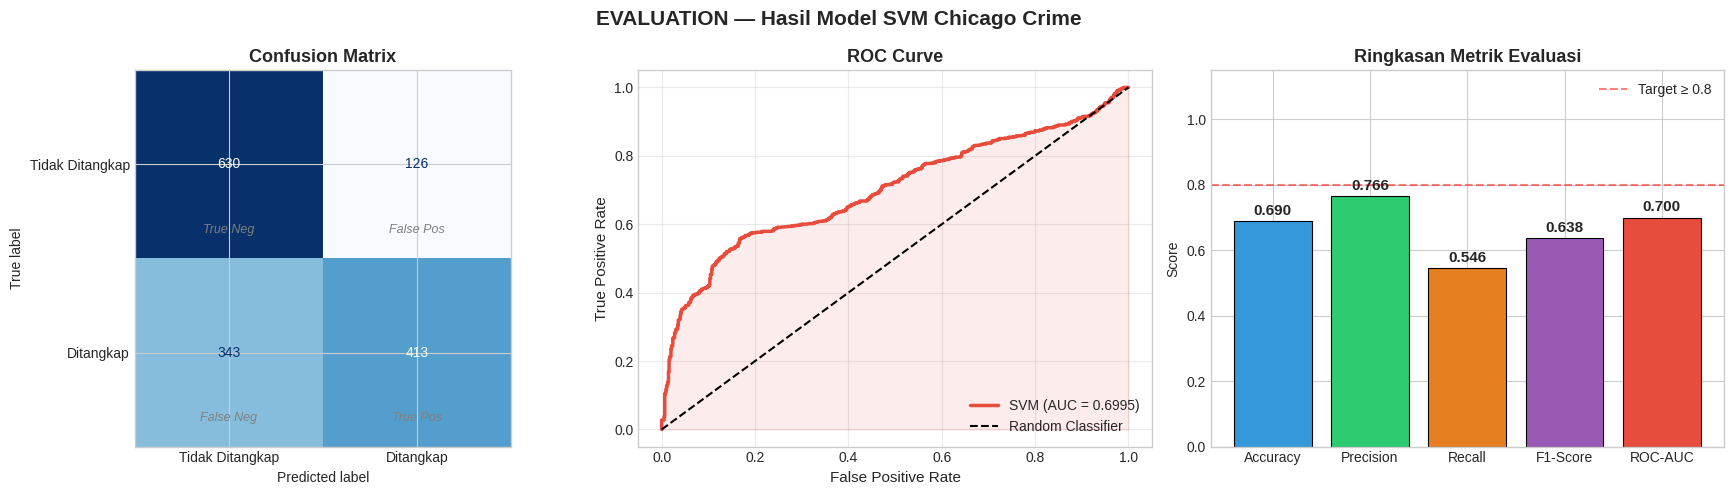

✅ Visualisasi Evaluasi selesai!


In [37]:
# VISUALISASI EVALUASI
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('EVALUATION — Hasil Model SVM Chicago Crime', 
             fontsize=15, fontweight='bold')

# Plot 1: Confusion Matrix
ax1 = axes[0]
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, 
                               display_labels=['Tidak Ditangkap', 'Ditangkap'])
disp.plot(ax=ax1, colorbar=False, cmap='Blues')
ax1.set_title('Confusion Matrix', fontweight='bold', fontsize=13)

# Tambahkan anotasi manual yang lebih jelas
for i in range(2):
    for j in range(2):
        label = 'True Neg' if (i==0 and j==0) else \
                'False Pos' if (i==0 and j==1) else \
                'False Neg' if (i==1 and j==0) else 'True Pos'
        ax1.text(j, i+0.35, label, ha='center', va='center', 
                fontsize=9, color='gray', style='italic')

# Plot 2: ROC Curve
ax2 = axes[1]
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
ax2.plot(fpr, tpr, color='#E74C3C', linewidth=2.5, label=f'SVM (AUC = {auc:.4f})')
ax2.plot([0, 1], [0, 1], 'k--', linewidth=1.5, label='Random Classifier')
ax2.fill_between(fpr, tpr, alpha=0.1, color='#E74C3C')
ax2.set_xlabel('False Positive Rate', fontsize=11)
ax2.set_ylabel('True Positive Rate', fontsize=11)
ax2.set_title('ROC Curve', fontweight='bold', fontsize=13)
ax2.legend(loc='lower right')
ax2.grid(True, alpha=0.4)

# Plot 3: Ringkasan Metrik
ax3 = axes[2]
metrik_names  = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
metrik_values = [accuracy, precision, recall, f1, auc]
colors_bar = ['#3498DB', '#2ECC71', '#E67E22', '#9B59B6', '#E74C3C']
bars = ax3.bar(metrik_names, metrik_values, color=colors_bar, 
               edgecolor='black', linewidth=0.8)
for bar, val in zip(bars, metrik_values):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
             f'{val:.3f}', ha='center', va='bottom', fontweight='bold', fontsize=11)
ax3.set_ylim(0, 1.15)
ax3.set_title('Ringkasan Metrik Evaluasi', fontweight='bold', fontsize=13)
ax3.set_ylabel('Score')
ax3.axhline(y=0.8, color='red', linestyle='--', alpha=0.5, label='Target ≥ 0.8')
ax3.legend()

plt.tight_layout()
plt.savefig('02_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Visualisasi Evaluasi selesai!")

# **Deployment  & Insight**

In [38]:
# Simpan model

import joblib
joblib.dump(best_model, 'svm_chicago_crime_model2.pkl')
print("💾 Model berhasil disimpan sebagai: svm_chicago_crime_model.pkl")

💾 Model berhasil disimpan sebagai: svm_chicago_crime_model.pkl



Generating insight visualizations...


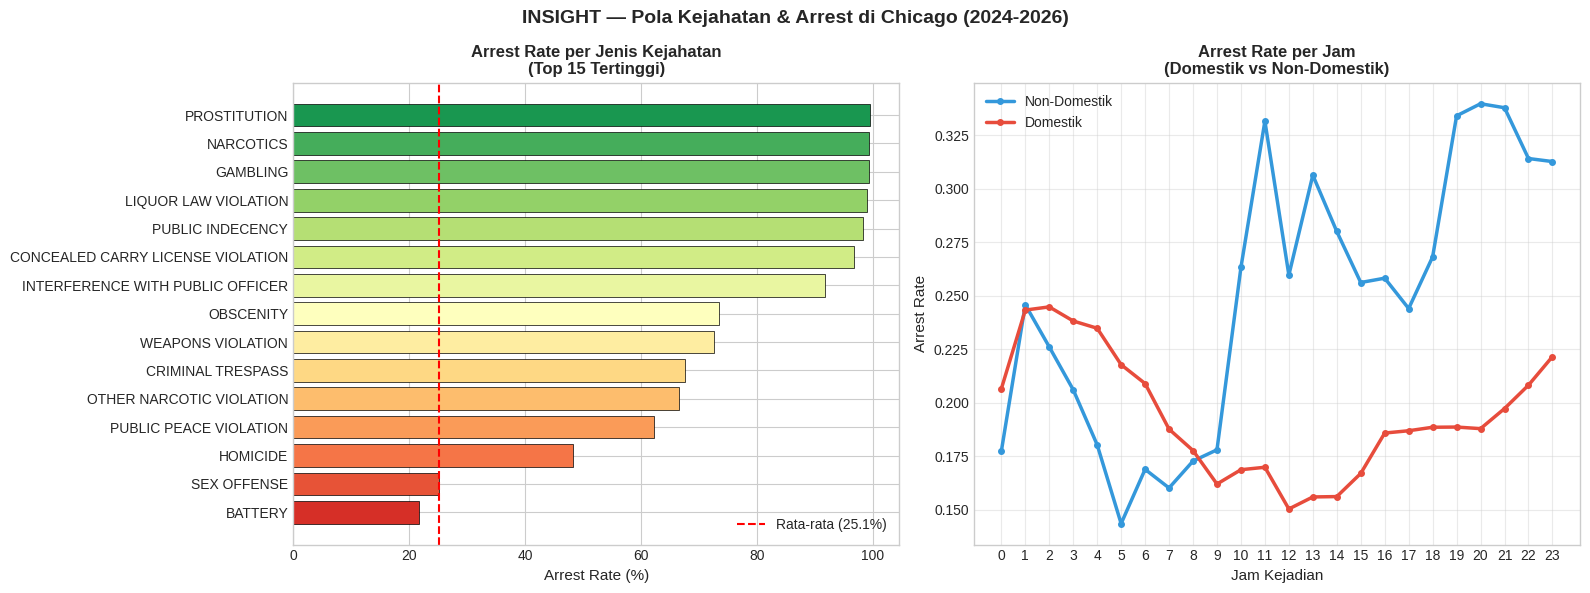

In [39]:
# Analisis Insight — Arrest Rate per Jenis Kejahatan
print("\nGenerating insight visualizations...")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('INSIGHT — Pola Kejahatan & Arrest di Chicago (2024-2026)', 
             fontsize=14, fontweight='bold')

# Plot 1: Arrest Rate per Jenis Kejahatan (Top 15)
ax1 = axes[0]
arrest_by_crime = df_clean.groupby('Primary Type')['Arrest'].agg(['mean', 'count'])
arrest_by_crime = arrest_by_crime[arrest_by_crime['count'] > 100]  # minimal 100 kasus
arrest_by_crime = arrest_by_crime.sort_values('mean', ascending=True).tail(15)
colors_crime = plt.cm.RdYlGn(np.linspace(0.1, 0.9, len(arrest_by_crime)))
ax1.barh(arrest_by_crime.index, arrest_by_crime['mean'] * 100, 
         color=colors_crime, edgecolor='black', linewidth=0.5)
ax1.set_xlabel('Arrest Rate (%)', fontsize=11)
ax1.set_title('Arrest Rate per Jenis Kejahatan\n(Top 15 Tertinggi)', fontweight='bold')
ax1.axvline(x=df_clean['Arrest'].mean() * 100, color='red', 
            linestyle='--', label=f'Rata-rata ({df_clean["Arrest"].mean()*100:.1f}%)')
ax1.legend()

# Plot 2: Arrest Rate per Jam (Heatmap style)
ax2 = axes[1]
hour_domestic = df_clean.groupby(['Hour', 'Domestic'])['Arrest'].mean().unstack()
hour_domestic.columns = ['Non-Domestik', 'Domestik']
hour_domestic.plot(kind='line', ax=ax2, linewidth=2.5, 
                   color=['#3498DB', '#E74C3C'], marker='o', markersize=4)
ax2.set_xlabel('Jam Kejadian', fontsize=11)
ax2.set_ylabel('Arrest Rate', fontsize=11)
ax2.set_title('Arrest Rate per Jam\n(Domestik vs Non-Domestik)', fontweight='bold')
ax2.set_xticks(range(0, 24))
ax2.legend()
ax2.grid(True, alpha=0.4)

plt.tight_layout()
plt.savefig('03_insight.png', dpi=150, bbox_inches='tight')
plt.show()

In [40]:
# DEPLOYMENT — Fungsi Prediksi

def prediksi_arrest(primary_type, location_description, hour, district, domestic):
    """
    Fungsi prediksi arrest berdasarkan karakteristik kejahatan.
    
    Parameters:
    -----------
    primary_type         : str  → Jenis kejahatan, contoh: 'NARCOTICS', 'THEFT'
    location_description : str  → Lokasi kejadian, contoh: 'STREET', 'RESIDENCE'
    hour                 : int  → Jam kejadian (0-23)
    district             : int  → Nomor distrik kepolisian
    domestic             : bool → True jika kejahatan domestik, False jika tidak
    """
    
    # Encoding input sesuai label encoder yang sudah difit
    primary_type_enc  = le_primary_type.transform([primary_type])[0]
    location_desc_enc = le_location_desc.transform([location_description])[0]
    domestic_int      = int(domestic)
    
    # Buat dataframe input sesuai FITUR final (5 kolom)
    input_data = pd.DataFrame([[
        primary_type_enc,
        location_desc_enc,
        hour,
        district,
        domestic_int
    ]], columns=FITUR)
    
    # Prediksi
    hasil        = best_model.predict(input_data)[0]
    probabilitas = best_model.predict_proba(input_data)[0]
    
    # Output
    label = "✅ DITANGKAP (Arrest = True)" if hasil == 1 else "❌ TIDAK DITANGKAP (Arrest = False)"
    print(f"   Hasil Prediksi   : {label}")
    print(f"   Probabilitas     : Tidak Ditangkap = {probabilitas[0]:.2%} | Ditangkap = {probabilitas[1]:.2%}")
    return hasil


# ============================================================
# Contoh Prediksi
# ============================================================

print("🚀 Contoh Penggunaan Model (Simulasi Prediksi Baru):")
print("-" * 55)

print("\n📝 Kasus 1 — Kejahatan Narkotika, di Jalanan, Malam Hari:")
prediksi_arrest(
    primary_type         = 'NARCOTICS',
    location_description = 'STREET',
    hour                 = 23,
    district             = 1,
    domestic             = False
)

print("\n📝 Kasus 2 — Pencurian, di Toko, Siang Hari:")
prediksi_arrest(
    primary_type         = 'THEFT',
    location_description = 'RETAIL STORE',
    hour                 = 14,
    district             = 3,
    domestic             = False
)

print("\n📝 Kasus 3 — Kekerasan Domestik, di Rumah, Malam Hari:")
prediksi_arrest(
    primary_type         = 'BATTERY',
    location_description = 'RESIDENCE',
    hour                 = 21,
    district             = 7,
    domestic             = True
)

🚀 Contoh Penggunaan Model (Simulasi Prediksi Baru):
-------------------------------------------------------

📝 Kasus 1 — Kejahatan Narkotika, di Jalanan, Malam Hari:
   Hasil Prediksi   : ✅ DITANGKAP (Arrest = True)
   Probabilitas     : Tidak Ditangkap = 23.13% | Ditangkap = 76.87%

📝 Kasus 2 — Pencurian, di Toko, Siang Hari:
   Hasil Prediksi   : ❌ TIDAK DITANGKAP (Arrest = False)
   Probabilitas     : Tidak Ditangkap = 66.81% | Ditangkap = 33.19%

📝 Kasus 3 — Kekerasan Domestik, di Rumah, Malam Hari:
   Hasil Prediksi   : ❌ TIDAK DITANGKAP (Arrest = False)
   Probabilitas     : Tidak Ditangkap = 66.69% | Ditangkap = 33.31%


np.int64(0)

In [41]:
sample = df_clean[['Primary Type', 'Location Description', 'Hour', 'District', 'Domestic', 'Arrest']].dropna()

arrested = sample[sample['Arrest'] == True].sample(3, random_state=42)
not_arrested = sample[sample['Arrest'] == False].sample(3, random_state=42)

result = pd.concat([arrested, not_arrested]).reset_index(drop=True)
print(result.to_string())

      Primary Type Location Description  Hour  District  Domestic  Arrest
0         HOMICIDE          GAS STATION    23       7.0     False    True
1        NARCOTICS             SIDEWALK    23      12.0     False    True
2        NARCOTICS               STREET    10       7.0     False    True
3  CRIMINAL DAMAGE               STREET    23       5.0     False   False
4          BATTERY            RESIDENCE    13      25.0      True   False
5          ASSAULT                ALLEY    18      22.0      True   False


In [42]:
print(classification_report(y_test, y_pred, target_names=['Tidak Ditangkap (0)', 'Ditangkap (1)']))
print(f"Accuracy  : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision : {precision_score(y_test, y_pred):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score  : {f1_score(y_test, y_pred):.4f}")

                     precision    recall  f1-score   support

Tidak Ditangkap (0)       0.65      0.83      0.73       756
      Ditangkap (1)       0.77      0.55      0.64       756

           accuracy                           0.69      1512
          macro avg       0.71      0.69      0.68      1512
       weighted avg       0.71      0.69      0.68      1512

Accuracy  : 0.6898
Precision : 0.7662
Recall    : 0.5463
F1-Score  : 0.6378
